# 1. Feature Transformation
A. To use PCA Algorithm for dimensionality reduction.
<br>You have a dataset that includes measurements for different variables on wine
(alcohol, ash, magnesium, and so on).<br>Apply PCA algorithm & transform this data
so that most variations in the measurements of the variables are captured by a small
number of principal components so that it is easier to distinguish between red and
white wine by inspecting these principal components.<br>
Dataset Link: https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv("Wine.csv")
df

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740,3
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750,3
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835,3
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840,3


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (178, 14)


In [4]:
# X = df.drop(columns=[target])
# y = df[target]
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
# 5. APPLY PCA (2 COMPONENTS)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [7]:

# Create reduced dataset
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Wine_Class"] = y.values

print("\nReduced Dataset:")
pca_df


Reduced Dataset:


,PC1,PC2,Wine_Class
0,3.316751,1.443463,1
1,2.209465,-0.333393,1
2,2.516740,1.031151,1
3,3.757066,2.756372,1
4,1.008908,0.869831,1
...,...,...,...
173,-3.370524,2.216289,3
174,-2.601956,1.757229,3
175,-2.677839,2.760899,3
176,-2.387017,2.297347,3


In [8]:

# 6. EXPLAINED VARIANCE
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

total = sum(pca.explained_variance_ratio_) * 100
print("Total Variance Captured:", round(total, 2), "%")



Explained Variance Ratio:
[0.36198848 0.1920749 ]
Total Variance Captured: 55.41 %


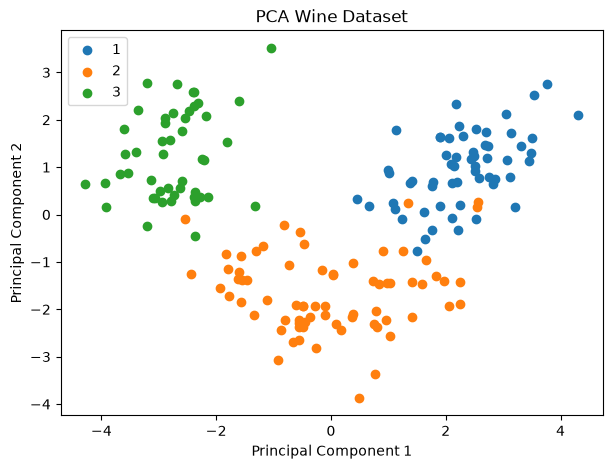

In [9]:
plt.figure(figsize=(7, 5))

for c in y.unique():
    plt.scatter(X_pca[y == c, 0], X_pca[y == c, 1], label=c)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Wine Dataset")
plt.legend()
plt.show()

In [ ]:
 # Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original Features:", X_scaled.shape[1])
print("Reduced Features:", pca.n_components_)   
print("Variance Captured:",round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

Original Features: 13
Reduced Features: 10
Variance Captured: 96.17 %
